# EDA — LIDC Lung Nodule Classification

[Competition](https://www.kaggle.com/competitions/lidc-lung-nodule-classification/overview) · EDA, metrics, visualizations

## 1. Data loading

Data loaded from: /Users/zakharstaryk/Downloads/scientificProject2/data
Training samples: 1986
Test samples: 280
Submission sample rows: 280


,id,image_id,object_id,patient_id,series_name,study_id,segmentMap,bbox,label,label_id
0,30930.000000-Recon 2 LOW DOSE THROUGH LUNGS-19...,30930.000000-Recon 2 LOW DOSE THROUGH LUNGS-19490,1,LIDC-IDRI-0939,1.3.6.1.4.1.14519.5.2.1.6279.6001.313835996725...,30930.000000-Recon 2 LOW DOSE THROUGH LUNGS-19490,"{'1': None, 'Calcification': ['Absent'], 'Inte...","[423, 258, 190, 425, 264, 193]",Moderately Unlikely,1
1,30930.000000-Recon 2 LOW DOSE THROUGH LUNGS-19...,30930.000000-Recon 2 LOW DOSE THROUGH LUNGS-19490,2,LIDC-IDRI-0939,1.3.6.1.4.1.14519.5.2.1.6279.6001.313835996725...,30930.000000-Recon 2 LOW DOSE THROUGH LUNGS-19490,"{'1': None, 'Calcification': ['Absent'], 'Inte...","[125, 217, 259, 132, 223, 263]",Moderately Unlikely,1
2,30930.000000-Recon 2 LOW DOSE THROUGH LUNGS-19...,30930.000000-Recon 2 LOW DOSE THROUGH LUNGS-19490,3,LIDC-IDRI-0939,1.3.6.1.4.1.14519.5.2.1.6279.6001.313835996725...,30930.000000-Recon 2 LOW DOSE THROUGH LUNGS-19490,"{'1': None, 'Calcification': ['Absent', 'Absen...","[111, 210, 367, 129, 236, 389]",Moderately Suspicious,2
3,30006.000000-NA-79830__1,30006.000000-NA-79830,1,LIDC-IDRI-0543,1.3.6.1.4.1.14519.5.2.1.6279.6001.792381786708...,30006.000000-NA-79830,"{'1': None, 'Calcification': ['Absent', 'Absen...","[423, 197, 390, 435, 214, 400]",Indeterminate,-1
4,30006.000000-NA-79830__2,30006.000000-NA-79830,2,LIDC-IDRI-0543,1.3.6.1.4.1.14519.5.2.1.6279.6001.792381786708...,30006.000000-NA-79830,"{'1': None, 'Calcification': ['Absent', 'Absen...","[399, 186, 411, 424, 212, 439]",Moderately Suspicious,2


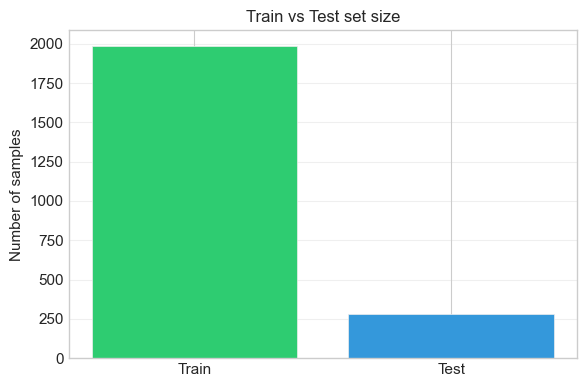

In [101]:
from pathlib import Path

try:
    from src.utils.config import DATA_DIR, BASE_DIR
except ImportError:
    BASE_DIR = Path.cwd()
    DATA_DIR = BASE_DIR / "data"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11})
sns.set_palette("husl")


def load_data():
    for base in [DATA_DIR / "archive", BASE_DIR / "archive", Path("archive"), DATA_DIR, Path(".")]:
        train_path = base / "train.parquet"
        test_path = base / "test.csv"
        sub_path = base / "sample_submission.csv"
        if train_path.exists() and test_path.exists():
            # Use PyArrow directly to avoid pandas/pyarrow extension-type conflicts
            train_df = pq.read_table(str(train_path)).to_pandas()
            test_df = pd.read_csv(test_path)
            submission_sample = pd.read_csv(sub_path) if sub_path.exists() else None
            return train_df, test_df, submission_sample, base


train_df, test_df, submission_sample, data_dir = load_data()
print(f"Data loaded from: {data_dir}")
print(f"Training samples: {len(train_df)}")
print(f"Test samples: {len(test_df)}")
if submission_sample is not None:
    print(f"Submission sample rows: {len(submission_sample)}")
display(train_df.head())

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Train", "Test"], [len(train_df), len(test_df)], color=["#2ecc71", "#3498db"])
ax.set_ylabel("Number of samples")
ax.set_title("Train vs Test set size")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 2. EDA

### 2.1 Shape and schema

In [103]:
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("\nTrain columns:", list(train_df.columns))
print("\nTrain dtypes:\n", train_df.dtypes)
train_df.info()

Train shape: (1986, 10)
Test shape: (280, 7)

Train columns: ['id', 'image_id', 'object_id', 'patient_id', 'series_name', 'study_id', 'segmentMap', 'bbox', 'label', 'label_id']

Train dtypes:
 id             object
image_id       object
object_id       int64
patient_id     object
series_name    object
study_id       object
segmentMap     object
bbox           object
label          object
label_id        int64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1986 entries, 0 to 1985
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           1986 non-null   object
 1   image_id     1986 non-null   object
 2   object_id    1986 non-null   int64 
 3   patient_id   1986 non-null   object
 4   series_name  1986 non-null   object
 5   study_id     1986 non-null   object
 6   segmentMap   1986 non-null   object
 7   bbox         1986 non-null   object
 8   label        1986 non-null   object
 9   label_id  

In [104]:
missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df) * 100).round(2)
pd.DataFrame({"missing": missing, "missing_%": missing_pct})[missing > 0].sort_values("missing", ascending=False)

,missing,missing_%


### 2.2 Label distribution

In [105]:
candidates = [c for c in train_df.columns if c.lower() in ("target", "label", "malignancy", "class", "cancer")]
if not candidates:
    for c in train_df.columns:
        if train_df[c].dtype in ("int64", "float64") and train_df[c].nunique() <= 20:
            candidates = [c]
            break
target_col = candidates[0] if candidates else train_df.columns[-1]
print(f"Using target column: '{target_col}'")

print("\nValue counts:")
print(train_df[target_col].value_counts(dropna=False))
print("\nProportions:")
print(train_df[target_col].value_counts(normalize=True, dropna=False).round(4))

Using target column: 'label'

Value counts:
label
Indeterminate            918
Moderately Unlikely      418
Moderately Suspicious    269
Highly Unlikely          250
Highly Suspicious        131
Name: count, dtype: int64

Proportions:
label
Indeterminate            0.4622
Moderately Unlikely      0.2105
Moderately Suspicious    0.1354
Highly Unlikely          0.1259
Highly Suspicious        0.0660
Name: proportion, dtype: float64


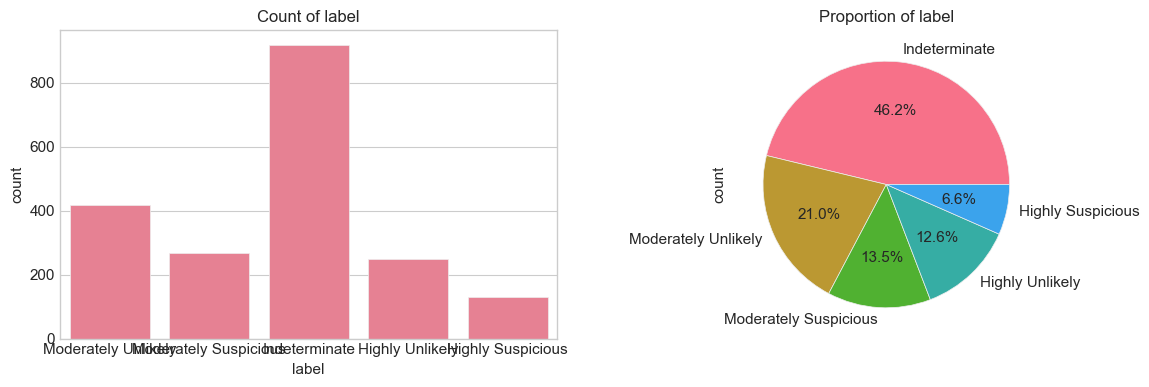

In [106]:
# Target distribution plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=train_df, x=target_col, ax=axes[0])
axes[0].set_title(f"Count of {target_col}")
train_df[target_col].value_counts().plot(kind="pie", ax=axes[1], autopct="%1.1f%%")
axes[1].set_title(f"Proportion of {target_col}")
plt.tight_layout()
plt.show()

### 2.4 Task and data

- **Task:** classify nodules (CT) — predict suspicion level (`label` / `label_id`).
- **Train:** 1986, **Test:** 280. Scans: `.nii`, bbox: `[x1,y1,z1,x2,y2,z2]`.
- **Imbalance:** many Indeterminate (~46%); handle separately.


### 2.5 CT slices and bbox (NIfTI + nibabel)

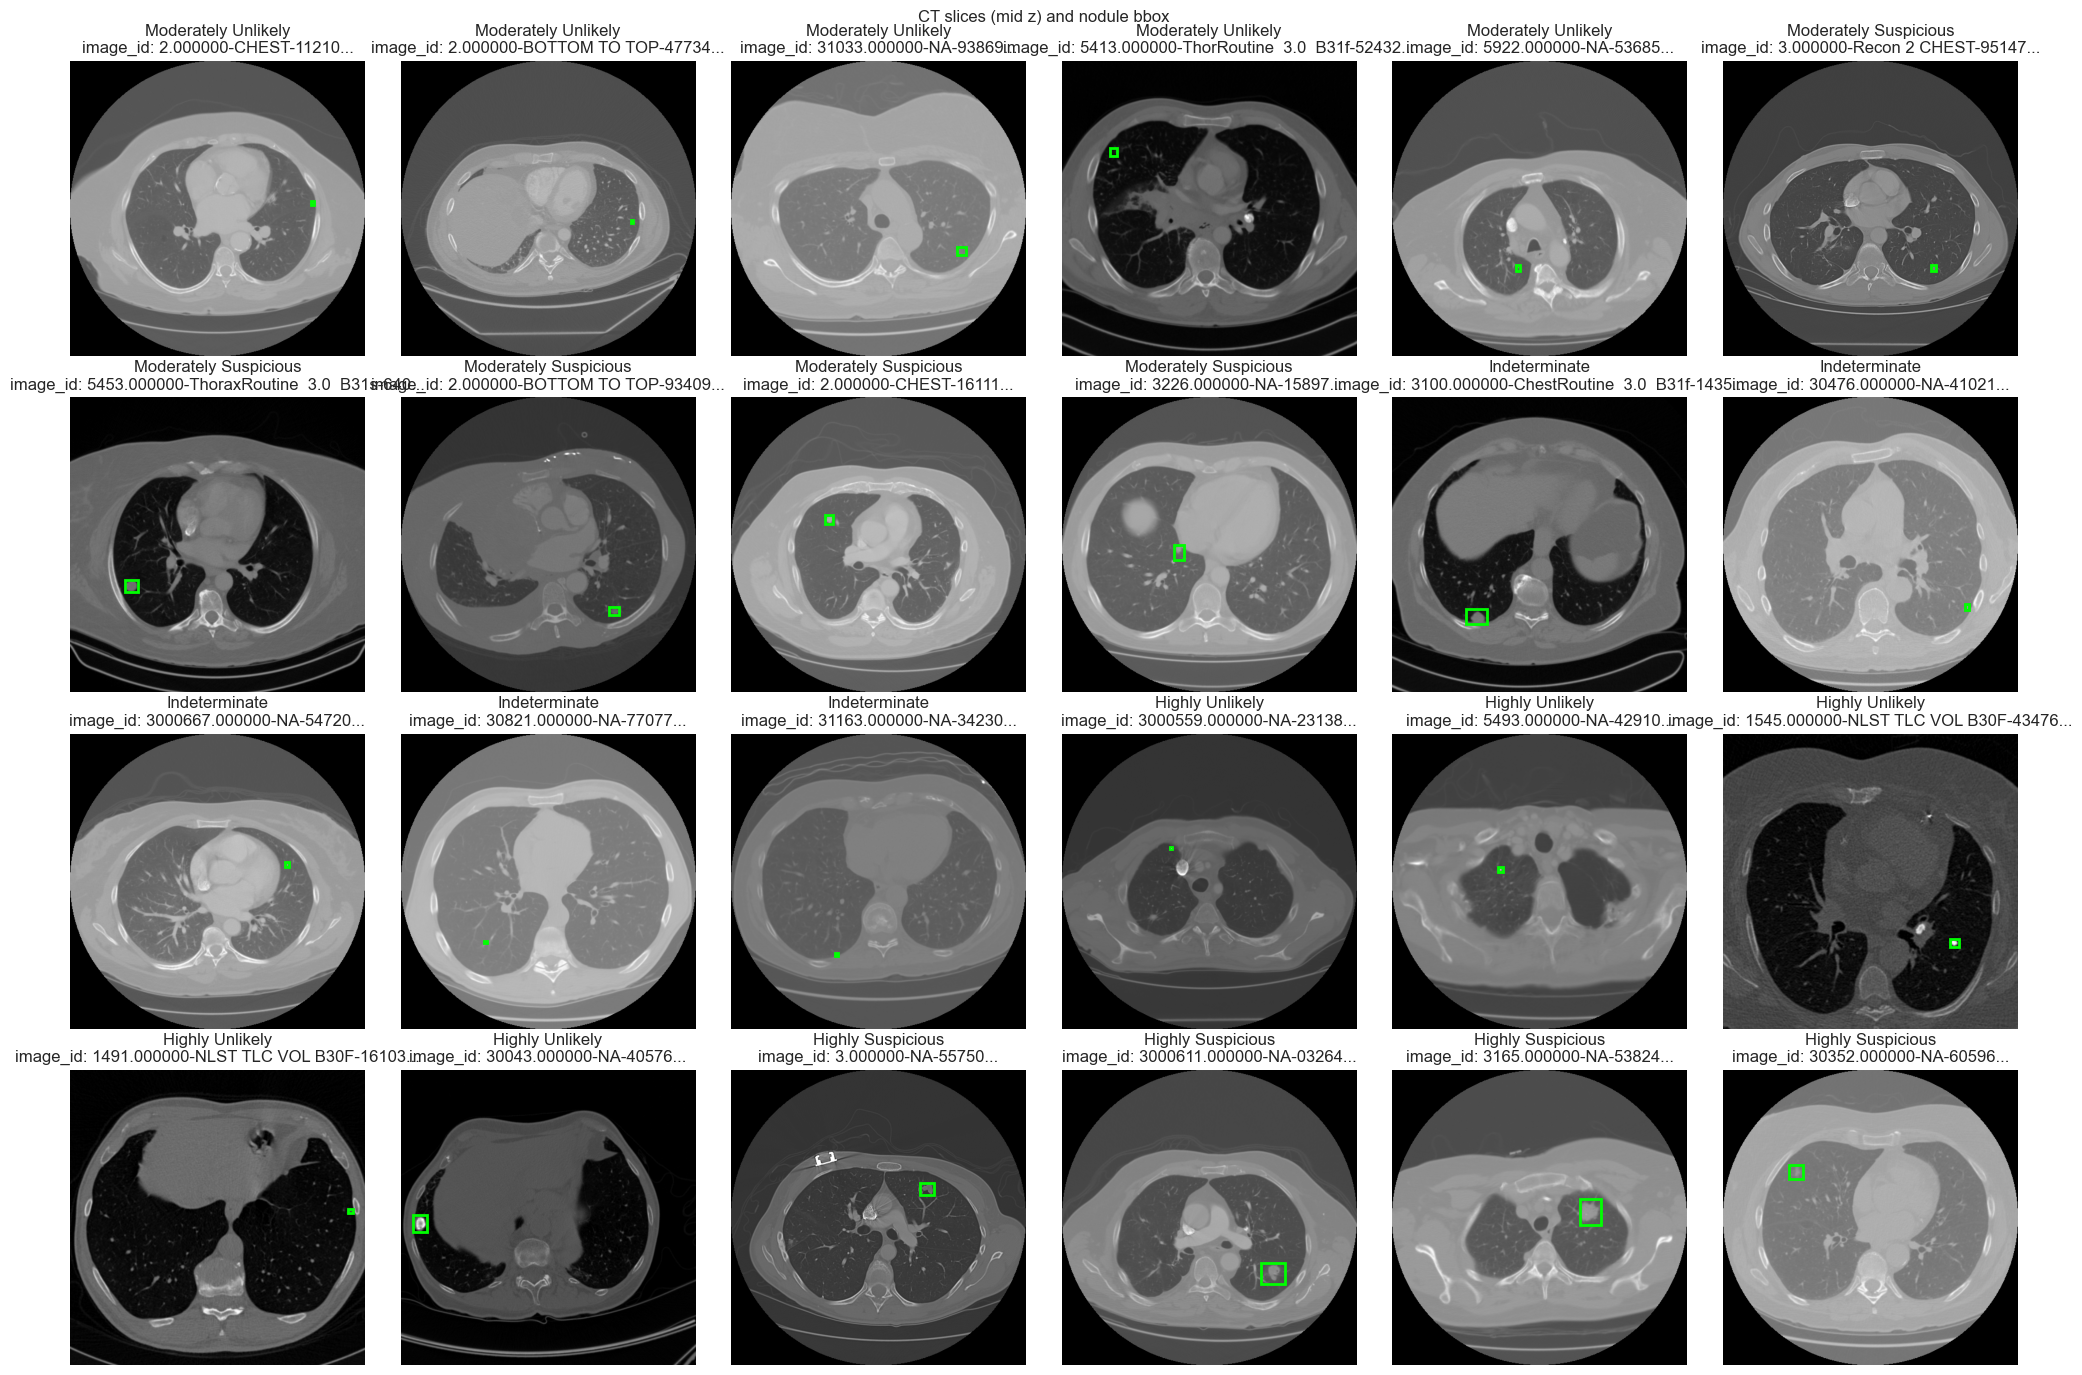

In [107]:
import ast

def parse_bbox(bbox):
    if isinstance(bbox, (list, tuple)) and len(bbox) >= 6:
        return [int(bbox[i]) for i in range(6)]
    s = str(bbox).strip("[]").replace(",", " ")
    parts = s.split()
    if len(parts) >= 6:
        return [int(parts[i]) for i in range(6)]
    return None

np.random.seed(42)
n_per_label = 5
samples = []
for label_val in train_df["label"].unique():
    g = train_df[train_df["label"] == label_val]
    n_take = min(n_per_label, len(g))
    samples.append(g.sample(n=n_take, random_state=42))
sample_per_label = pd.concat(samples, ignore_index=True).head(24)
if len(sample_per_label) == 0:
    sample_per_label = train_df.head(6)

try:
    import nibabel as nib
    HAS_NIBABEL = True
except ImportError:
    HAS_NIBABEL = False
    print("nibabel not installed. Install: pip install nibabel")

if HAS_NIBABEL:
    n_show = min(24, len(sample_per_label))
    fig, axes = plt.subplots(4, 6, figsize=(20, 14))
    axes = axes.ravel()
    for idx, (_, row) in enumerate(sample_per_label.iterrows()):
        if idx >= n_show:
            break
        ax = axes[idx]
        image_id = row["image_id"]
        label = row["label"]
        bbox = parse_bbox(row["bbox"])
        nii_path = None
        for base in [data_dir, data_dir.parent / "archive", Path("archive"), BASE_DIR / "archive"]:
            p = base / f"{image_id}.nii"
            if p.exists():
                nii_path = p
                break
        if nii_path is None:
            ax.text(0.5, 0.5, f"File not found:\n{image_id[:50]}...", ha="center", va="center", fontsize=8, color="white")
            ax.set_facecolor("#333")
            ax.set_title(f"{label}")
            ax.axis("off")
            continue
        img = nib.load(str(nii_path))
        vol = img.get_fdata()
        if bbox is None or vol.size == 0:
            ax.set_title(f"{label}")
            ax.axis("off")
            continue
        x1, y1, z1, x2, y2, z2 = bbox
        z_mid = (z1 + z2) // 2
        z_mid = max(0, min(z_mid, vol.shape[2] - 1))
        slice_2d = vol[:, :, z_mid]
        ax.imshow(slice_2d.T, origin="lower", cmap="gray")
        rect = plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="lime", linewidth=2)
        ax.add_patch(rect)
        ax.set_title(f"{label}\nimage_id: {image_id[:40]}...")
        ax.axis("off")
    for j in range(idx + 1, n_show):
        axes[j].axis("off")
    plt.suptitle("CT slices (mid z) and nodule bbox", fontsize=12)
    plt.tight_layout()
    plt.show()
else:
    print("Sample records (image_id, label, bbox):")
    display(sample_per_label[["image_id", "label", "bbox"]].head(10))

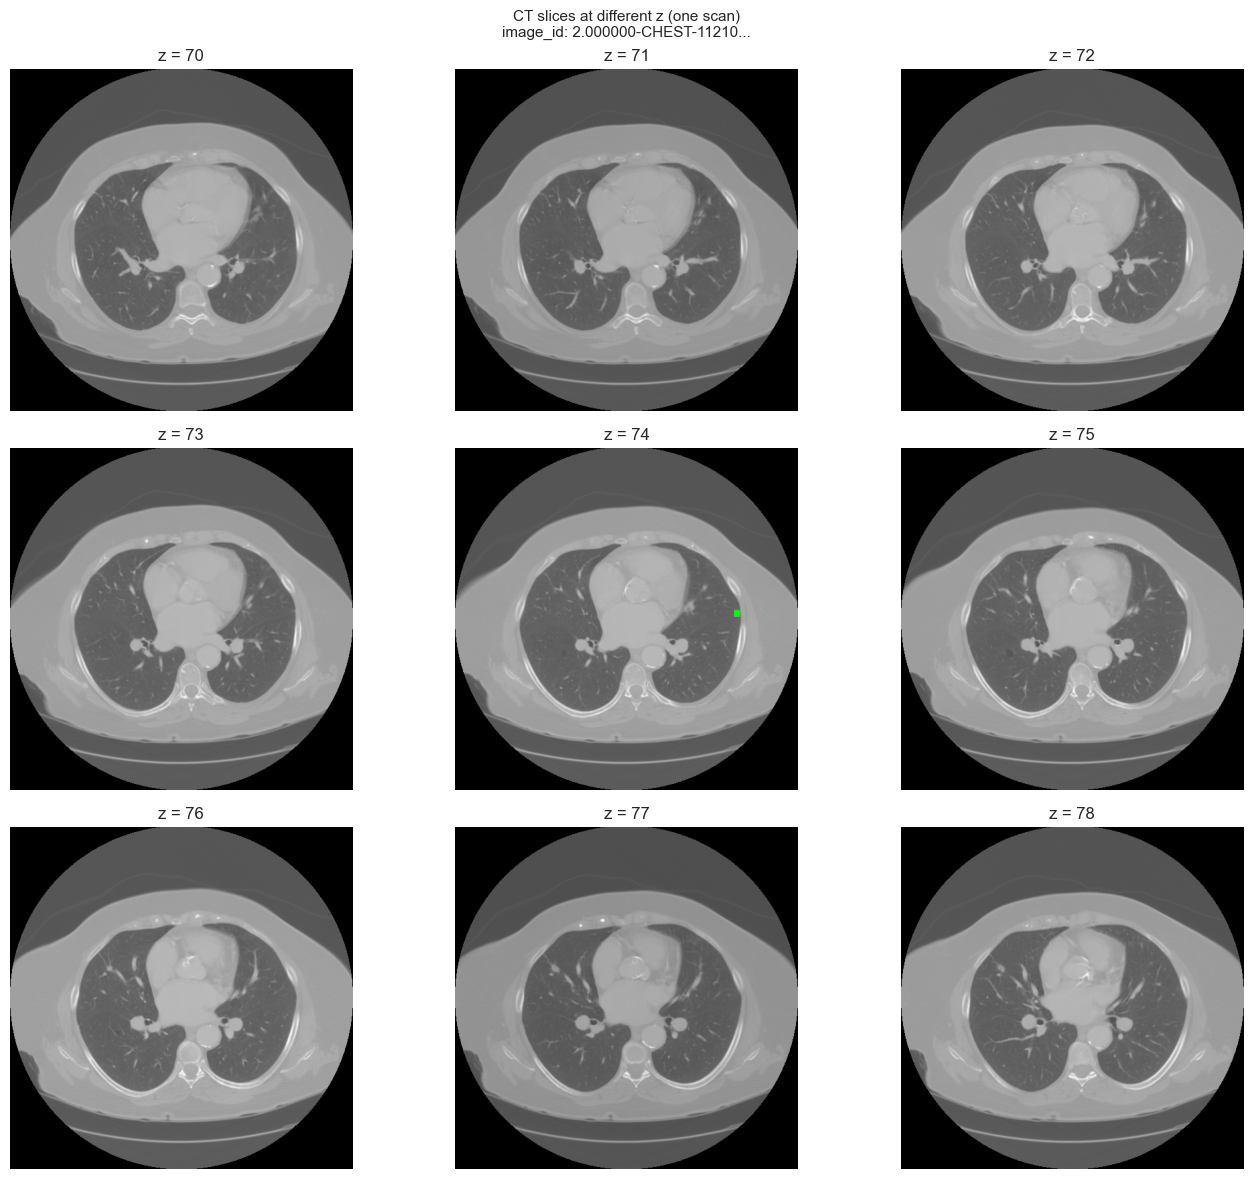

In [108]:
# Additional CT slices: multiple z-positions for one scan
try:
    import nibabel as nib
    _row = sample_per_label.iloc[0]
    _image_id = _row["image_id"]
    _bbox = parse_bbox(_row["bbox"])
    _nii_path = None
    for _base in [data_dir, data_dir.parent / "archive", Path("archive"), BASE_DIR / "archive"]:
        _p = _base / f"{_image_id}.nii"
        if _p.exists():
            _nii_path = _p
            break
    if _nii_path is not None and _bbox is not None:
        _img = nib.load(str(_nii_path))
        _vol = _img.get_fdata()
        z1, z2 = _bbox[2], _bbox[5]
        z_mid = (z1 + z2) // 2
        fig2, axes2 = plt.subplots(3, 3, figsize=(14, 12))
        axes2 = axes2.ravel()
        for k, z_off in enumerate([-4, -3, -2, -1, 0, 1, 2, 3, 4]):
            z_slice = max(0, min(z_mid + z_off, _vol.shape[2] - 1))
            axes2[k].imshow(_vol[:, :, z_slice].T, origin="lower", cmap="gray")
            if z_off == 0:
                x1, y1, x2, y2 = _bbox[0], _bbox[1], _bbox[3], _bbox[4]
                rect = plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="lime", linewidth=2)
                axes2[k].add_patch(rect)
            axes2[k].set_title(f"z = {z_slice}")
            axes2[k].axis("off")
        plt.suptitle(f"CT slices at different z (one scan)\nimage_id: {_image_id[:50]}...", fontsize=11)
        plt.tight_layout()
        plt.show()
    else:
        print("NIfTI not found or bbox missing for first sample; skip extra slices.")
except Exception as e:
    print("Extra slices skipped:", e)


### 2.3 Numeric columns and correlation


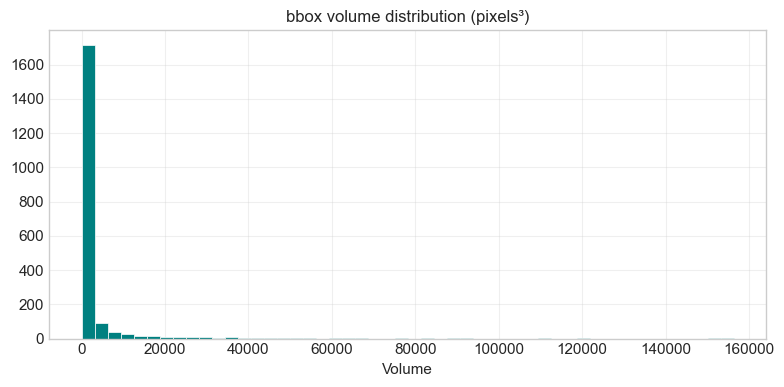

In [109]:
# bbox volume (pixels³)
def parse_bbox(bbox):
    if isinstance(bbox, (list, tuple)) and len(bbox) >= 6:
        return [int(bbox[i]) for i in range(6)]
    s = str(bbox).strip("[]").replace(",", " ")
    parts = s.split()
    return [int(parts[i]) for i in range(6)] if len(parts) >= 6 else None

volumes = []
for b in train_df["bbox"]:
    r = parse_bbox(b)
    if r:
        volumes.append((r[3]-r[0]) * (r[4]-r[1]) * (r[5]-r[2]))
volumes = pd.Series(volumes)
fig, ax = plt.subplots(figsize=(8, 4))
volumes.hist(bins=50, ax=ax, color="teal", edgecolor="white")
ax.set_title("bbox volume distribution (pixels³)")
ax.set_xlabel("Volume")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

/var/folders/65/2djjc53n6gq33p7yxntrl6cr0000gn/T/ipykernel_17358/1296006904.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=vol_by_label, x="label", y="_vol", palette="Set3")


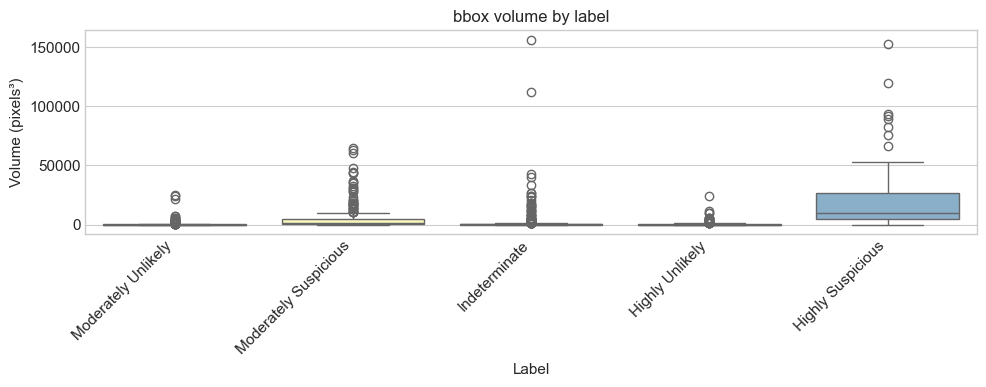

In [110]:
# Volume by label (boxplot)
train_df["_vol"] = train_df["bbox"].apply(lambda b: (lambda r: (r[3]-r[0])*(r[4]-r[1])*(r[5]-r[2]) if r else None)(parse_bbox(b)))
vol_by_label = train_df.dropna(subset=["_vol"])
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=vol_by_label, x="label", y="_vol", palette="Set3")
ax.set_ylabel("Volume (pixels³)")
ax.set_xlabel("Label")
ax.set_title("bbox volume by label")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
train_df.drop(columns=["_vol"], inplace=True)

### 3.1 Metric: Log Loss

Pros: probability calibration, single score. Cons: sensitive to imbalance and extreme probabilities. Clip to [ε, 1-ε].


### 3.2 Complementary metrics

| Metric | Captures |
|---------|----------|
| AUC-ROC | Ranking, robust to imbalance |
| Sensitivity | Missed cancer (critical) |
| Specificity | False alarms |
| F1 / Brier | Precision/recall balance, calibration |
